
# WORLD HAPPINESS ANALYSIS – 2019

### Python Data Analytics Project

**Submitted By:** Sahil Maurya

**Project Domain:** Data Science and Data Analytics

**Programming Language:** Python

**Platform:** Google Colab

**Dataset:** World Happiness Report 2019


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
df = pd.read_csv('/content/2019.csv')

In [ ]:
# Basic Overview: head(), tail(), shape, info(), describe()
print("First 5 rows:")
display(df.head())

print("\nLast 5 rows:")
display(df.tail())

print("\nShape (rows, columns):", df.shape)

print("\nInfo:")
df.info()

print("\nDescribe:")
display(df.describe())

First 5 rows:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
0,1,Finland,7.769,1.340,1.587,0.986,0.596,0.153,0.393
1,2,Denmark,7.600,1.383,1.573,0.996,0.592,0.252,0.410
2,3,Norway,7.554,1.488,1.582,1.028,0.603,0.271,0.341
3,4,Iceland,7.494,1.380,1.624,1.026,0.591,0.354,0.118
4,5,Netherlands,7.488,1.396,1.522,0.999,0.557,0.322,0.298



Last 5 rows:


,Overall rank,Country or region,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
151,152,Rwanda,3.334,0.359,0.711,0.614,0.555,0.217,0.411
152,153,Tanzania,3.231,0.476,0.885,0.499,0.417,0.276,0.147
153,154,Afghanistan,3.203,0.350,0.517,0.361,0.000,0.158,0.025
154,155,Central African Republic,3.083,0.026,0.000,0.105,0.225,0.235,0.035
155,156,South Sudan,2.853,0.306,0.575,0.295,0.010,0.202,0.091



Shape (rows, columns): (156, 9)

Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Overall rank                  156 non-null    int64  
 1   Country or region             156 non-null    object 
 2   Score                         156 non-null    float64
 3   GDP per capita                156 non-null    float64
 4   Social support                156 non-null    float64
 5   Healthy life expectancy       156 non-null    float64
 6   Freedom to make life choices  156 non-null    float64
 7   Generosity                    156 non-null    float64
 8   Perceptions of corruption     156 non-null    float64
dtypes: float64(7), int64(1), object(1)
memory usage: 11.1+ KB

Describe:


,Overall rank,Score,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
count,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000,156.000000
mean,78.500000,5.407096,0.905147,1.208814,0.725244,0.392571,0.184846,0.110603
std,45.177428,1.113120,0.398389,0.299191,0.242124,0.143289,0.095254,0.094538
min,1.000000,2.853000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,39.750000,4.544500,0.602750,1.055750,0.547750,0.308000,0.108750,0.047000
50%,78.500000,5.379500,0.960000,1.271500,0.789000,0.417000,0.177500,0.085500
75%,117.250000,6.184500,1.232500,1.452500,0.881750,0.507250,0.248250,0.141250
max,156.000000,7.769000,1.684000,1.624000,1.141000,0.631000,0.566000,0.453000


In [ ]:
# Question 1: Which 10 countries have the highest happiness scores?

top10 = df.sort_values("Score", ascending=False).head(10)
display(top10[["Overall rank", "Country or region", "Score"]])

,Overall rank,Country or region,Score
0,1,Finland,7.769
1,2,Denmark,7.600
2,3,Norway,7.554
3,4,Iceland,7.494
4,5,Netherlands,7.488
5,6,Switzerland,7.480
6,7,Sweden,7.343
7,8,New Zealand,7.307
8,9,Canada,7.278
9,10,Austria,7.246


In [ ]:
# Question 2: Which 10 countries have the lowest happiness scores?

bottom10 = df.sort_values("Score", ascending=True).head(10)
display(bottom10[["Overall rank", "Country or region", "Score"]])

,Overall rank,Country or region,Score
155,156,South Sudan,2.853
154,155,Central African Republic,3.083
153,154,Afghanistan,3.203
152,153,Tanzania,3.231
151,152,Rwanda,3.334
150,151,Yemen,3.380
149,150,Malawi,3.410
148,149,Syria,3.462
147,148,Botswana,3.488
146,147,Haiti,3.597


In [ ]:
# Question 3: Calculate mean, median, minimum and maximum happiness score

scores = df["Score"].to_numpy()   # NumPy array

print("Mean   :", round(np.mean(scores), 3))
print("Median :", round(np.median(scores), 3))
print("Minimum:", round(np.min(scores), 3),
      "->", df.loc[df["Score"].idxmin(), "Country or region"])
print("Maximum:", round(np.max(scores), 3),
      "->", df.loc[df["Score"].idxmax(), "Country or region"])
print("Std Dev:", round(np.std(scores, ddof=1), 3))

Mean   : 5.407
Median : 5.38
Minimum: 2.853 -> South Sudan
Maximum: 7.769 -> Finland
Std Dev: 1.113


In [ ]:
# Question 4: Compare average happiness score by broad region (if a region column is available)

if "Region" in df.columns:
    print("Region column found in 2019.csv")
else:
    print("2019.csv has no region column. Borrowing 'Region' from 2015.csv of the same dataset.")
    try:
        df15 = pd.read_csv(os.path.join(path, "2015.csv"))[["Country", "Region"]]
        df = df.merge(df15, left_on="Country or region", right_on="Country", how="left")
        df.drop(columns="Country", inplace=True)
        df["Region"] = df["Region"].fillna("Unmapped")
    except Exception as e:
        print("Could not load 2015.csv:", e)

if "Region" in df.columns:
    print("\nCountries per region:")
    print(df["Region"].value_counts())

    region_avg = (df.groupby("Region")["Score"]
                    .agg(["count", "mean"])
                    .round(3)
                    .sort_values("mean", ascending=False))
    display(region_avg)

2019.csv has no region column. Borrowing 'Region' from 2015.csv of the same dataset.
Could not load 2015.csv: name 'os' is not defined


In [ ]:
# Question 5: Find the countries with the highest GDP per capita and social support values

print("Top 10 countries by GDP per capita:")
display(df.nlargest(10, "GDP per capita")[["Country or region", "GDP per capita", "Score"]])

print("\nTop 10 countries by Social support:")
display(df.nlargest(10, "Social support")[["Country or region", "Social support", "Score"]])

# Countries appearing in both top-10 lists
both = set(df.nlargest(10, "GDP per capita")["Country or region"]) & \
       set(df.nlargest(10, "Social support")["Country or region"])
print("\nIn both top-10 lists:", both)

Top 10 countries by GDP per capita:


,Country or region,GDP per capita,Score
28,Qatar,1.684,6.374
13,Luxembourg,1.609,7.090
33,Singapore,1.572,6.262
20,United Arab Emirates,1.503,6.825
50,Kuwait,1.500,6.021
15,Ireland,1.499,7.021
2,Norway,1.488,7.554
5,Switzerland,1.452,7.480
75,Hong Kong,1.438,5.430
18,United States,1.433,6.892



Top 10 countries by Social support:


,Country or region,Social support,Score
3,Iceland,1.624,7.494
0,Finland,1.587,7.769
2,Norway,1.582,7.554
1,Denmark,1.573,7.600
7,New Zealand,1.557,7.307
15,Ireland,1.553,7.021
10,Australia,1.548,7.228
14,United Kingdom,1.538,7.054
86,Turkmenistan,1.538,5.247
82,Mongolia,1.531,5.285



In both top-10 lists: {'Norway', 'Ireland'}


In [ ]:
# Question 6: Check missing values and duplicates

print("Missing values per column:")
print(df.isnull().sum())
print("\nTotal missing values:", df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate country names:", df["Country or region"].duplicated().sum())

Missing values per column:
Overall rank                    0
Country or region               0
Score                           0
GDP per capita                  0
Social support                  0
Healthy life expectancy         0
Freedom to make life choices    0
Generosity                      0
Perceptions of corruption       0
Score band                      0
dtype: int64

Total missing values: 0

Duplicate rows: 0
Duplicate country names: 0


In [ ]:
# Extra EDA: Pandas filtering, value_counts(), groupby() and NumPy correlation

# Filtering: countries with score above the mean
mean_score = df["Score"].mean()
above_avg = df[df["Score"] > mean_score]
print("Countries above average score:", len(above_avg), "of", len(df))

# value_counts + groupby on score bands
df["Score band"] = pd.cut(df["Score"], bins=[0, 4, 5, 6, 7, 10],
                          labels=["Below 4", "4-5", "5-6", "6-7", "Above 7"])
print("\nCountries per score band:")
print(df["Score band"].value_counts().sort_index())

print("\nAverage of each factor by score band:")
display(df.groupby("Score band", observed=True)[["GDP per capita", "Social support",
        "Healthy life expectancy", "Freedom to make life choices",
        "Generosity", "Perceptions of corruption"]].mean().round(3))

# NumPy correlation of each factor with Score
factors = ["GDP per capita", "Social support", "Healthy life expectancy",
           "Freedom to make life choices", "Generosity", "Perceptions of corruption"]
for col in factors:
    r = np.corrcoef(df[col].to_numpy(), df["Score"].to_numpy())[0, 1]
    print(f"Correlation of {col:30s} with Score: {r:.3f}")

Countries above average score: 77 of 156

Countries per score band:
Score band
Below 4    16
4-5        43
5-6        45
6-7        36
Above 7    16
Name: count, dtype: int64

Average of each factor by score band:


,GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption
Score band,,,,,,
Below 4,0.344,0.747,0.421,0.243,0.206,0.109
4-5,0.608,1.006,0.529,0.349,0.184,0.090
5-6,0.988,1.297,0.789,0.374,0.158,0.076
6-7,1.197,1.404,0.887,0.466,0.172,0.102
Above 7,1.375,1.528,1.013,0.548,0.270,0.285


Correlation of GDP per capita                 with Score: 0.794
Correlation of Social support                 with Score: 0.777
Correlation of Healthy life expectancy        with Score: 0.780
Correlation of Freedom to make life choices   with Score: 0.567
Correlation of Generosity                     with Score: 0.076
Correlation of Perceptions of corruption      with Score: 0.386


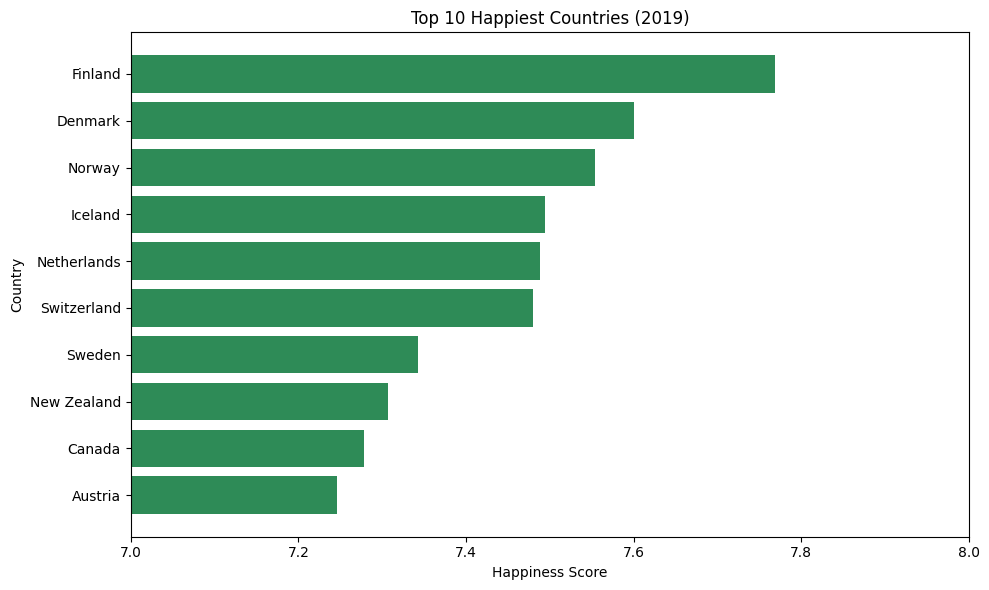

In [ ]:
# Chart 1: Bar chart of top 10 happiest countries

plt.figure(figsize=(10, 6))
plt.barh(top10["Country or region"][::-1], top10["Score"][::-1], color="seagreen")
plt.xlabel("Happiness Score")
plt.ylabel("Country")
plt.title("Top 10 Happiest Countries (2019)")
plt.xlim(7, 8)
plt.tight_layout()
plt.show()

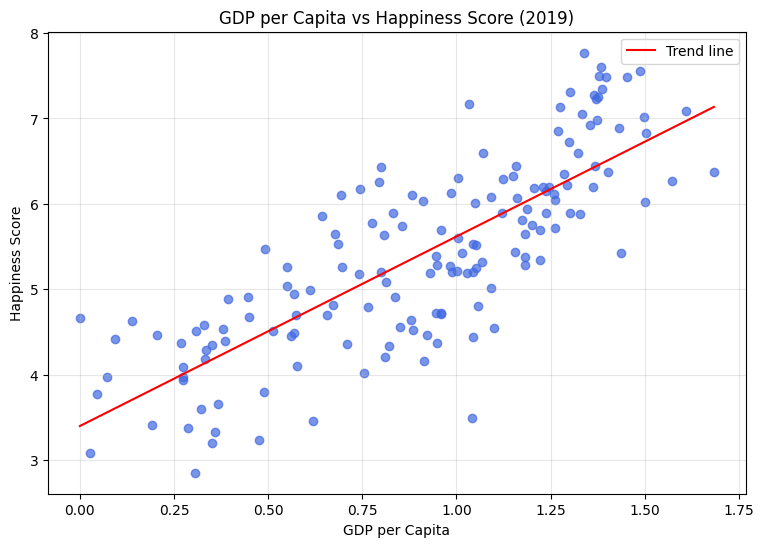

In [ ]:
# Chart 2: Scatter plot of GDP per capita vs Happiness Score

x = df["GDP per capita"].to_numpy()
y = df["Score"].to_numpy()

plt.figure(figsize=(9, 6))
plt.scatter(x, y, alpha=0.7, color="royalblue")

# Trend line using NumPy
m, c = np.polyfit(x, y, 1)
plt.plot(np.sort(x), m * np.sort(x) + c, color="red", label="Trend line")

plt.xlabel("GDP per Capita")
plt.ylabel("Happiness Score")
plt.title("GDP per Capita vs Happiness Score (2019)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

##  Observation

After analysing the World Happiness Report 2019 dataset,
the following observations were made:

1. The dataset contains happiness scores and related
   factors for different countries.

2. Finland achieved the highest happiness score in 2019.

3. Countries have different happiness scores, showing
   variations in their reported levels of well-being.

4. GDP per capita and social support show a positive
   relationship with happiness score.

5. Healthy life expectancy and freedom to make life
   choices are also associated with happiness.

6. The correlation heatmap helps identify relationships
   between different numerical variables.

7. Data visualization makes it easier to compare
   countries and understand happiness patterns.

8. The analysis shows associations between happiness
   and different factors, but correlation does not
   prove cause and effect.

## Conclusion

The World Happiness Report 2019 dataset provides
useful information about happiness levels across
different countries.

Through Python, Pandas, NumPy, Matplotlib and
Seaborn, we analysed happiness scores and different
factors such as GDP per capita, social support,
healthy life expectancy and freedom.

The analysis helps us understand the relationship
between these factors and happiness scores.
However, correlation does not necessarily mean
causation.

This project improved our understanding of
Python programming and data analysis.